In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

rng = np.random.default_rng(42)


In [ ]:
# Network parameters
N_ASSETS = 1000
HORIZON = 20
GAMMA = 1                    # Left this as 1 since accidents are as bad short term and long term?
ANNUAL_BUDGET = 200.0        # total across the network
FAILURE_PENALTY = 5.0        # per asset per year in state 4
N_STATES = 5                 # 0=Very Good ... 4=Critical

STATES = ["Very Good", "Good", "Fair", "Poor", "Critical"]
ACTIONS = ["do_nothing", "minor", "major"]
ACTION_COST = {"do_nothing": 0.0, "minor": 1.0, "major": 8.0}

INITIAL_DIST = np.array([1.0, 0.0, 0.0, 0.0, 0.0])   # all start Very Good

In [6]:
# Transition matrices. No maintance tends to degrade asset, maintance tends to improve asset.
P_DO_NOTHING = np.array([
    [0.85, 0.15, 0.00, 0.00, 0.00],
    [0.00, 0.80, 0.20, 0.00, 0.00],
    [0.00, 0.00, 0.70, 0.30, 0.00],
    [0.00, 0.00, 0.00, 0.60, 0.40],
    [0.00, 0.00, 0.00, 0.00, 1.00],
])

P_MINOR = np.array([
    [0.95, 0.05, 0.00, 0.00, 0.00],
    [0.10, 0.85, 0.05, 0.00, 0.00],
    [0.00, 0.15, 0.80, 0.05, 0.00],
    [0.00, 0.00, 0.20, 0.75, 0.05],
    [0.00, 0.00, 0.00, 0.25, 0.75],
])

P_MAJOR = np.array([
    [1.00, 0.00, 0.00, 0.00, 0.00],
    [0.30, 0.70, 0.00, 0.00, 0.00],
    [0.10, 0.60, 0.30, 0.00, 0.00],
    [0.00, 0.30, 0.60, 0.10, 0.00],
    [0.00, 0.20, 0.50, 0.30, 0.00],
])

P = {"do_nothing": P_DO_NOTHING, "minor": P_MINOR, "major": P_MAJOR}

# Sanity check: each row sums to 1
for name, m in P.items():
    assert np.allclose(m.sum(axis=1), 1), f"{name} rows do not sum to 1"
print("Transition matrices OK")

Transition matrices OK


In [ ]:
def simulate_network(policy_fn, n_assets=N_ASSETS, horizon=HORIZON,
                     budget=ANNUAL_BUDGET, rng=None):
    """Run one Monte Carlo trajectory. Returns per-year histories."""
    if rng is None:
        rng = np.random.default_rng()
    states = rng.choice(N_STATES, size=n_assets, p=INITIAL_DIST) # List of initial states 
    # Lists that record the states 
    hist_critical = np.zeros(horizon + 1, dtype=int)
    hist_spend = np.zeros(horizon)
    hist_penalty = np.zeros(horizon)
    hist_critical[0] = (states == 4).sum()

    for t in range(horizon):
        actions = policy_fn(states, budget)                     # list of action strings
        spend = sum(ACTION_COST[a] for a in actions)
        # advance each asset
        new_states = np.empty_like(states)
        for i, (s, a) in enumerate(zip(states, actions)):
            new_states[i] = rng.choice(N_STATES, p=P[a][s])
        states = new_states
        hist_critical[t + 1] = (states == 4).sum()
        hist_spend[t] = spend
        hist_penalty[t] = FAILURE_PENALTY * (states == 4).sum()

    return {"critical": hist_critical, "spend": hist_spend,
            "penalty": hist_penalty}


def total_discounted_cost(hist, gamma=GAMMA):   # prioritise fixing criticals early
    t = np.arange(len(hist["spend"]))
    return (gamma ** t * (hist["spend"] + hist["penalty"])).sum()

Policies

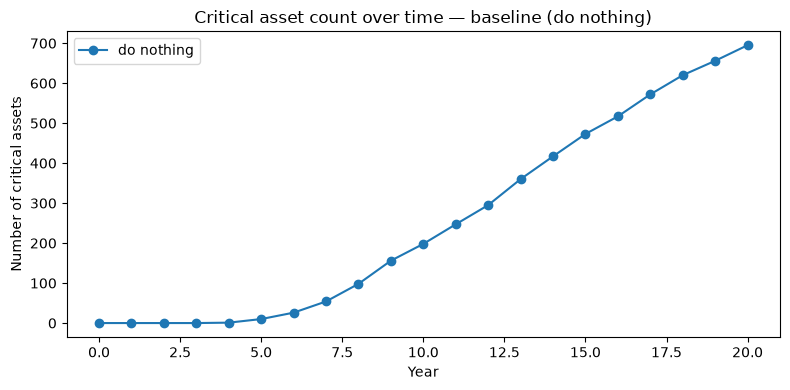

Total discounted cost (do nothing): 12969.1


In [15]:
def policy_do_nothing(states, budget):
    return ["do_nothing"] * len(states)

run = simulate_network(policy_do_nothing, rng=np.random.default_rng(0))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(run["critical"], marker="o", label="do nothing")
ax.set_xlabel("Year"); ax.set_ylabel("Number of critical assets")
ax.set_title("Critical asset count over time — baseline (do nothing)")
ax.legend(); plt.tight_layout(); plt.show()

print(f"Total discounted cost (do nothing): {total_discounted_cost(run):.1f}")

## Validation against Markov chain theory

For the do-nothing policy, assets evolve as independent homogeneous Markov
chains, so the exact state distribution after $t$ years is

$$
\pi_t = \pi_0 \, P^t,
$$

where:

- $\pi_0$ is the initial state distribution
- $P$ is the do-nothing transition matrix
- $\pi_t$ is the distribution over the 5 states at year $t$

At the 20-year horizon: $\pi_{20} = \pi_0 \, P^{20}$.

Since assets are i.i.d. under this policy, the number of critical assets at
year $t$ is $\text{Binomial}(N, [\pi_t]_4)$, giving an exact mean and variance
to compare against the Monte Carlo simulation.


In [23]:
pi0 = INITIAL_DIST
pi_T = pi0 @ np.linalg.matrix_power(P_DO_NOTHING, HORIZON)
expected_critical_T = N_ASSETS * pi_T[4]

print("Probability distribution of an asset at year 20 is:\n ",pi_T) # The probability distribution of an asset at year 20. 70% chance of being critical!
print("Expected number of critical at year HORIZON:\n ",expected_critical_T)

Probability distribution of an asset at year 20 is:
  [0.03875953 0.08169095 0.08745868 0.08700454 0.7050863 ]
Expected number of critical at year HORIZON:
  705.086302495561
